<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_07_data_transformation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS 4487 Assignment 7: Data Transformation with Airbnb Listings

In this assignment, you will:
- Load the Airbnb dataset you cleaned in Assignment 6
- Apply data transformation techniques like scaling, binning, encoding, and feature creation
- Make the dataset easier to use for tasks like pricing analysis, guest segmentation, or listing recommendations
- Practice writing up your analysis clearly so a business audience — like a host, marketing manager, or city partner — could understand it

## Why This Matters

Airbnb analysts, hosts, and city partners rely on clean and well-structured data to make smart decisions. Whether they’re adjusting prices, identifying high-performing listings, or designing better guest experiences, they need data that’s transformed, organized, and ready for use.

This assignment helps you practice that kind of real-world thinking: taking messy real data and getting it ready for action.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_07_data_transformation.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

Choose a City & Upload Your Dataset
📥 Follow these steps:

Go to: https://insideairbnb.com/get-the-data/
Choose a city you’re interested in.
Download the file named: listings.csv.gz under that city.
In your notebook:
Open the left sidebar
Click the folder icon 📁
Click the upload icon ⬆️ and choose your listings.csv.gz file
Use the file path /content/listings.csv.gz when loading your data.
Import standard libraries (pandas, numpy, seaborn, matplotlib)

## 1. Setup and Load Your Data

You'll be working with the `cleaned_airbnb_data_6.csv` file you exported from Assignment 6. (Note: If you had significant errors with assignment 6, you can use the file named "airbnb_listings.csv" in the DataSets folder on GitHub as a backup starting point.)

### Do the following:
In Google Colab:
- Click the folder icon on the left sidebar
- Use the upload button to add your CSV file to the session
- Then use the code block below to read it into your notebook

Before getting started, make sure you import the libraries you'll need for this assignment:
- `pandas`, `numpy` for data manipulation
- `matplotlib.pyplot`, `seaborn` for visualizations


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/cleaned_airbnb_data_6.csv")
df.head()

,id,listing_url,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,host_url,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,360,https://www.airbnb.com/rooms/360,2026-06-30,city scrape,Denver’s Peaceful Oasis for Travel Nurses & No...,Enjoy the famous Colorado weather and unplug i...,NaN,https://a0.muscache.com/pictures/monet/Select-...,666,https://www.airbnb.com/users/show/666,...,4.99,4.98,4.90,2017-BFN-0002177,NaN,1,1,0,0,1.94
1,364,https://www.airbnb.com/rooms/364,2026-07-02,previous scrape,Lodo / RiNo LOFT via airport train,"Modern 1,000 square foot loft in the heart of ...",NaN,https://a0.muscache.com/pictures/11766413/a2c5...,783,https://www.airbnb.com/users/show/783,...,4.96,4.65,4.71,NaN,NaN,1,1,0,0,0.42
2,592,https://www.airbnb.com/rooms/592,2026-06-30,city scrape,private,This room is in the basement. It does not hav...,NaN,https://a0.muscache.com/pictures/ba522ff9-84c9...,933,https://www.airbnb.com/users/show/933,...,4.96,4.84,4.88,2021-BFN-0000578,NaN,1,0,1,0,1.05
3,686,https://www.airbnb.com/rooms/686,2026-06-30,city scrape,Alexandra's Queen Bed Room Long-term Rental Only,Thanks for visiting my Queen Bed Room for LONG...,NaN,https://a0.muscache.com/pictures/108112/e6d5d3...,990,https://www.airbnb.com/users/show/990,...,4.91,4.87,4.82,NaN,NaN,1,0,1,0,1.16
4,1940,https://www.airbnb.com/rooms/1940,2026-06-30,city scrape,"Baker Studio Pet-friendly, Walkable, Patio",Private studio retreat in a charming historic ...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,2150,https://www.airbnb.com/users/show/2150,...,4.99,4.90,4.90,2018-BFN-0002596,NaN,2,2,0,0,2.42


## 2. Check for Skew in a Numeric Column

### Business framing:  

Airbnb listings can have a wide range of values for things like price, availability, or reviews. These kinds of distributions can be hard to visualize, summarize, or model.

### Do the following:
Choose one **numeric column** that appears skewed and do the following:
- Plot a histogram
- Apply a transformation (e.g., log or other method)
- Plot again to compare

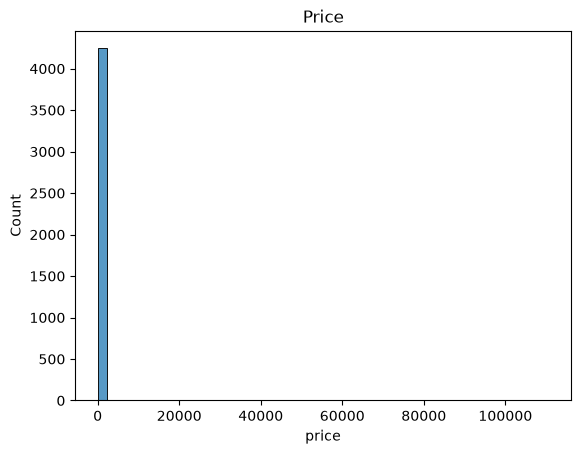

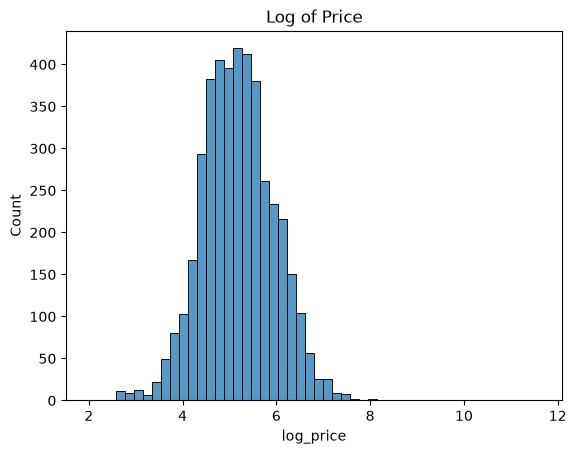

In [2]:
sns.histplot(df['price'], bins=50)
plt.title('Price')
plt.show()

df['log_price'] = np.log(df['price'])

sns.histplot(df['log_price'], bins=50)
plt.title('Log of Price')
plt.show()


### Reflection:
1. What column did you examine?
2. What transformation did you try, and why?
3. How did the transformed version help make the data more usable for analysis or stakeholder review?

### ✍️ Your Response: 🔧
1. I looked at price.

2. I used a log transformation. Most listings are a few hundred dollars a night, but one is 110,616.60, so the first histogram is basically one tall bar on the left and you can't see anything else. Log shrinks the really big numbers a lot more than the small ones.

3. The log histogram looks like a normal bell shape, so you can actually see where most listings fall. It would be easier to show someone the second chart, but I'd have to explain that the axis is log dollars and not real dollars.


## 3. Scale Two Numeric Columns

### Business framing:

If an analyst wanted to compare listing price to number of nights required, or create a model that weighs both, those values need to be on a similar scale.

### Do the following:
- Pick two numeric columns with different value ranges (e.g. one column may have a min of 0 and a max of 255; another column may have a min of 100 and a max of 400)
- Use Min-Max scaling on one column (the range should be “shrinked” down to just 0-1)
- Use Z-score Normalization (aka standardization) on the other column.
- Add 2 new columns to the dataset. These 2 new columns should be the ones you just created.

In [3]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Min-Max scale
minmax = MinMaxScaler()
df['availability_365_minmax'] = minmax.fit_transform(df[['availability_365']])

# Z-score scale
zscore = StandardScaler()
df['number_of_reviews_zscore'] = zscore.fit_transform(df[['number_of_reviews']])

df[['availability_365_minmax', 'number_of_reviews_zscore']].describe()

,availability_365_minmax,number_of_reviews_zscore
count,4939.000000,4.939000e+03
mean,0.564872,-2.301819e-17
std,0.336144,1.000101e+00
min,0.000000,-5.707957e-01
25%,0.246575,-5.469480e-01
50%,0.643836,-4.038620e-01
75%,0.876712,1.048882e-01
max,1.000000,1.372191e+01



### Reflection:
1. What two columns did you scale, and which methods did you use?
2. When might these scaled values be more useful than the originals?
3. Who at Airbnb might benefit from this transformation and why?

### ✍️ Your Response: 🔧
1. I used Min-Max scaling on availability_365 and Z-score on number_of_reviews.

2. The originals are hard to compare because availability goes from 0 to 365 and reviews go from 0 to 1,798. After scaling, availability is between 0 and 1, and reviews are centered around 0. That matters if a model uses both columns, because otherwise the one with bigger numbers would count for more just for being bigger.

3. A data scientist building a model would use this the most. An analyst could use the z-score too, since it shows how far a listing is from the average. The listing with the most reviews is about 13.7 standard deviations above average.


## 4. Group a Numeric Column into Categories

### Business framing:  

Let’s say an Airbnb marketing team wants to segment listings by review activity. They don’t want exact numbers — they just want to know if a listing has “low,” “medium,” or “high” review volume.

### Do the following:

- Choose a numeric column that could be grouped (e.g., reviews, availability).
- You’ll want to group the values of this column into 3 or 4 bins
- Create a new column. The values of this column will be the labels: “Low”, “Medium”, and “High.” These labels should correspond to your bins.

In [4]:
df['review_group'] = pd.qcut(df['number_of_reviews'], q=3, labels=['Low', 'Medium', 'High'])

print(df['review_group'].value_counts())

review_group
Low       1734
High      1634
Medium    1571
Name: count, dtype: int64


### Reflection:
1. What column did you group, and how many categories did you use?
2. Why might someone prefer this grouped view over raw numbers?
3. Who would this help at Airbnb, and how?

### ✍️ Your Response: 🔧
1. I grouped number_of_reviews into 3 categories: Low, Medium, and High. I used qcut so each group has about the same number of listings.

2. It's easier to read. "High" tells you more at a glance than a number like 85, because you don't have to know what counts as a lot of reviews.

3. The marketing team. They could send different messages to each group, like tips on getting first reviews for the Low group. One thing to watch is that the cutoffs come from this Denver data, so "High" here might not be high in a bigger city.


## 5. Create Two New Business-Relevant Variables

### Business framing:  

Stakeholders often want to know things like: What’s the cost per night? Are listings geared toward long-term stays? These kinds of features aren’t always in the dataset — analysts create them.

### Do the following:

- Think of two new columns you can create using the data you already have.
  - One might be a ratio or interaction between columns (e.g., price ÷ nights).
  - The other might be a flag based on a condition (e.g., stays longer than 30 days).
- Add the new columns to your DataFrame.

In [5]:
df['price_per_person'] = df['price'] / df['accommodates']

df['long_term_stay'] = (df['minimum_nights'] >= 30).astype(int)

df[['price_per_person', 'long_term_stay']].head()

,price_per_person,long_term_stay
0,53.175000,0
1,10.783333,1
2,40.000000,0
3,44.270000,1
4,95.860000,0


### Reflection:
1. What two new columns did you create and why?
2. Who would use them (e.g., host, manager, or platform)?
3. How could they help someone make a better decision?

### ✍️ Your Response: 🔧
1. I made price_per_person, which is price divided by accommodates, and long_term_stay, which is 1 if the minimum stay is 30 nights or more and 0 if not. A place that sleeps 8 will cost more than a studio, so price by itself isn't a fair comparison. The flag separates monthly rentals from regular vacation stays.

2. A host or a pricing analyst would use price_per_person. The platform or a city partner would use long_term_stay.

3. A host could check if they charge more per guest than similar listings and adjust. The flag lets someone look at short stays and long stays separately, since they are pretty different kinds of rentals.


## 6. Encode a Categorical Column

### Business framing:  

Let’s say you’re helping the Airbnb data science team build a model to predict booking rates. Categorical columns like `room_type`, `neighbourhood`, or `cancellation_policy` can’t be used in models unless they’re converted to numbers.

### Do the following:
- Choose one categorical column from your dataset (e.g., room type or neighborhood group)
- Decide on an encoding method:
  - Use one-hot encoding for nominal (unordered) categories
  - Use ordinal encoding (a ranking) only if the categories have a clear order
- Apply the encoding using `pandas` or another tool
- Add the new encoded column(s) to your DataFrame

In [6]:
df = pd.get_dummies(df, columns=['room_type'])

df.filter(like='room_type').head()

,room_type_Entire home/apt,room_type_Hotel room,room_type_Private room,room_type_Shared room
0,True,False,False,False
1,True,False,False,False
2,False,False,True,False
3,False,False,True,False
4,True,False,False,False


### Reflection:
1. What column did you encode and why?
2. What encoding method did you use?
3. How could this transformation help a pricing model, dashboard, or business report?

### ✍️ Your Response: 🔧
1. I encoded room_type. It's text, and a model can't use text.

2. One-hot encoding with pd.get_dummies. The four room types don't have a real order, so ranking them 1 to 4 wouldn't make sense.

3. Each room type is now its own True/False column, so a pricing model can figure out how much an entire home adds to the price compared to a private room. A dashboard could also use these columns to filter or count listings by room type.


## 7. Export Cleaned Data

Before wrapping up, export your cleaned Airbnb dataset to a CSV file. You'll need this file for **Assignment 11**, where you'll use the data in a regression model.

### Do the following:
Make sure your data has:
- Cleaned and consistent column values
- Proper data types for each column
- Any unnecessary columns removed

This file should be the version of your dataset that you’d feel confident sharing with a teammate or using for deeper analysis.



```
# Explanation:
# - "cleaned_airbnb_data_7.csv" is the name of the file that will be saved
# - index=False prevents pandas from writing row numbers into the CSV
# - The file will be saved to your working directory (in Colab, you'll need to download it manually. Once you see the data in your files tab, just click on the three dots, then click “download”)
# - YOU MAY NEED TO PRESS “RUN” MULTIPLE TIMES IN ORDER FOR IT TO SHOW UP
# - FOR SOME DEVICES, IT MAY TAKE A FEW MINUTES BEFORE YOUR FILE SHOWS UP

```

In [7]:
df = df.dropna(axis=1, how='all')

df.to_csv("cleaned_airbnb_data_7.csv", index=False)

## 8. Reflection

You’ve applied the same kinds of transformation techniques used in real Airbnb analytics projects — from pricing engines to host tools to tourism dashboards.

Now step back and reflect.

### Reflection:
1. What transformation step felt most important or interesting?
2. Which of your changes would be most useful to a host, analyst, or city planner?
3. If you were going to build a tool or dashboard, what would you do next with this data?
4. How does this relate to your customized learning outcome you created in canvas?



### ✍️ Your Response: 🔧

1. The log transformation on price was the most interesting. The first histogram was useless because of one huge price, and one line of code made it readable.

2. I think price_per_person would be the most useful for a host, since it lets them compare their price to places of a different size. A city planner would probably care more about the long_term_stay flag.

3. I would deal with the missing prices and the 110,616.60 listing first, since those are still in the data. After that I'd build a dashboard where a host picks a neighborhood and room type and sees the typical price per person.

4. One of my learning outcomes is a before and after case study for my dental clients using show rates and cost per lead. Cost per lead is a ratio just like price_per_person, so I'd build it the same way. The scaling part also applies, because show rate is a percent and cost per lead is in dollars, and they'd need to be on the same scale to go on one chart.


## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_07_data_transformation.ipynb"